John S. Anvik, 2026  
University of Lethbridge Student ID: 001224816

# Candidate-level match model using the 60 s window features

This notebook combines:

* **the structure of notebook 03**: one row per (event, candidate song type), a binary `match` target, a grouped train/test split and grouped CV by `event_id`, tuning on top-1 candidate-selection accuracy, and prediction by picking the candidate with the highest P(match) in each event;
* **the input features of notebook 21**: the neighbours' song counts in the last 60 s (`*window*` columns), the focal male's last two song types, and the time since his last two songs.

**Predictors on each candidate row**

| Group | Columns | Notes |
|---|---|---|
| Window features | every `*window*` column except `target`, `others` and `candidate_*` | Same selection rule as notebook 21. Identical for every candidate in an event. |
| Candidate identity | `candidate_ust` | Needed so the forest can learn song-specific responses to the window features. Without it, event-level constants cannot separate candidates. |
| Own song history (types) | `focal_last_1_ust`, `focal_last_2_ust` | Raw song types as factors, as in notebook 21. |
| Own song history (timing) | `focal_time_since_last_1`, `focal_time_since_last_2` | Seconds since the focal male's last two songs. |

**Deliberately not used** (they are notebook 03's candidate-aligned features): `candidate_n_ust_window` and `candidate_matches_M*_k_last_UST`.

Import Packages

In [1]:
# data.table is loaded first so that dplyr's first()/last()/between() take precedence
library(data.table)
library(tidyverse)
library(tidymodels)
library(vip)
library(ranger)
library(furrr)
set.seed(42)

Warning message:
"package 'data.table' was built under R version 4.5.3"
Warning message:
"package 'tidyverse' was built under R version 4.5.3"
Warning message:
"package 'ggplot2' was built under R version 4.5.3"
Warning message:
"package 'tibble' was built under R version 4.5.3"
Warning message:
"package 'tidyr' was built under R version 4.5.3"
Warning message:
"package 'readr' was built under R version 4.5.3"
Warning message:
"package 'purrr' was built under R version 4.5.3"
Warning message:
"package 'dplyr' was built under R version 4.5.3"
Warning message:
"package 'lubridate' was built under R version 4.5.3"
── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::between()     masks data.ta

Settings

In [2]:
MODEL_NAME <- "candidate_match_window60"

CANDIDATE_DIR <- "data/by_id"
RESULTS_DIR   <- "data/2026_results"

# Own-song history lags. Notebook 21 uses lags 1 and 2 (its 3rd lag is commented out).
OWN_LAGS <- 1:2

# In notebook 21 the n_ust_*_window counts reach the model as factors
# (as.factor(across(contains("UST"))) is case-insensitive, so it also catches "n_ust_*_window").
# TRUE reproduces that; FALSE treats the counts as numeric.
WINDOW_AS_FACTOR <- TRUE

# Notebook 21 used drop_na(). In candidate data a missing feature belongs to the whole event,
# so TRUE drops every event that has an NA in any predictor (this keeps exactly one match per event).
# FALSE keeps those events and imputes in the recipe (median for numeric, "unknown" for factors).
DROP_NA_EVENTS <- TRUE

Load candidate-level data (the window columns are already in the candidate files)

In [3]:
candidate_files <- list.files(CANDIDATE_DIR, pattern = "_candidate_classification\\.csv$", full.names = TRUE)
if (length(candidate_files) == 0) stop("No *_candidate_classification.csv files found in ", CANDIDATE_DIR)

# To test only a single classifier, uncomment the next line:
# candidate_files <- candidate_files[1]

# Window columns, selected the way notebook 21 does it:
# contains("window"), minus "target" and "others" -- and minus the candidate-specific candidate_* columns.
select_window_cols <- function(col_names) {
    has_window <- str_detect(col_names, regex("window", ignore_case = TRUE))
    excluded   <- str_detect(col_names, regex("target|others", ignore_case = TRUE)) |
                  str_starts(col_names, "candidate_")
    col_names[has_window & !excluded]
}

ID_COLS <- c("focal_male", "focal_id", "male_number", "event_id", "match_class")

build_male_data <- function(song_data, id_value, number_value, source_name) {
    male_prefix   <- paste0("M", number_value)
    own_type_cols <- paste0(male_prefix, "_", OWN_LAGS, "_last_UST")
    own_time_cols <- paste0("time_since_", male_prefix, "_", OWN_LAGS, "_last_song")
    window_cols   <- select_window_cols(names(song_data))

    required_columns <- c("event_id", "candidate_ust", "match", own_type_cols, own_time_cols)
    missing_columns  <- setdiff(required_columns, names(song_data))
    if (length(missing_columns) > 0) {
        stop(sprintf("Missing required columns in %s for %s: %s",
                     source_name, male_prefix, paste(missing_columns, collapse = ", ")))
    }
    if (length(window_cols) == 0) {
        stop(sprintf("No window columns found in %s. Check select_window_cols().", source_name))
    }

    # Standardised names for the own-history features
    own_type_new <- paste0("focal_last_", OWN_LAGS, "_ust")
    own_time_new <- paste0("focal_time_since_last_", OWN_LAGS)

    male_data <- song_data %>%
        filter(as.character(male_number) == number_value) %>%
        select(event_id, candidate_ust, match, all_of(window_cols),
               all_of(setNames(own_type_cols, own_type_new)),
               all_of(setNames(own_time_cols, own_time_new))) %>%
        mutate(
            focal_male    = paste0(id_value, "_", male_prefix),
            focal_id      = id_value,
            male_number   = number_value,
            candidate_ust = as.factor(as.character(candidate_ust)),
            match_class   = factor(if_else(match == 1, "match", "no_match"), levels = c("no_match", "match")),
            across(all_of(own_type_new), ~ as.factor(as.character(.x)))
        ) %>%
        select(-match) %>%
        relocate(focal_male, focal_id, male_number, event_id, candidate_ust, match_class)

    if (WINDOW_AS_FACTOR) {
        male_data <- male_data %>% mutate(across(all_of(window_cols), as.factor))
    }

    predictor_cols  <- setdiff(names(male_data), ID_COLS)
    n_events_before <- n_distinct(male_data$event_id)

    if (DROP_NA_EVENTS) {
        na_events <- male_data %>%
            filter(if_any(all_of(predictor_cols), is.na)) %>%
            distinct(event_id)
        male_data <- male_data %>% anti_join(na_events, by = "event_id")
    }

    event_checks <- male_data %>%
        group_by(event_id) %>%
        summarise(n_candidates = n(), n_matches = sum(match_class == "match"), .groups = "drop")
    if (nrow(event_checks) == 0 || any(event_checks$n_candidates < 2) || any(event_checks$n_matches != 1)) {
        stop(sprintf("Invalid candidate events for %s_%s in %s", id_value, male_prefix, source_name))
    }

    attr(male_data, "window_cols")         <- window_cols
    attr(male_data, "predictor_cols")      <- predictor_cols
    attr(male_data, "n_events_dropped_na") <- n_events_before - n_distinct(male_data$event_id)
    male_data
}

model_data_by_male <- list_flatten(map(candidate_files, function(candidate_file) {
    song_data     <- read_csv(candidate_file, show_col_types = FALSE)
    focal_ids     <- song_data %>% distinct(ID) %>% pull(ID)
    focal_numbers <- unique(as.character(song_data$male_number))
    focal_numbers <- focal_numbers[!is.na(focal_numbers)]
    if (length(focal_ids) != 1 || length(focal_numbers) == 0) {
        stop(sprintf("Expected one focal ID and at least one male_number in %s", candidate_file))
    }
    map(focal_numbers, function(focal_number) {
        build_male_data(song_data, focal_ids, focal_number, source_name = candidate_file)
    })
}))
names(model_data_by_male) <- map_chr(model_data_by_male, ~ unique(.x$focal_male))

In [4]:
# Overview of the candidate data actually used for modelling
map_dfr(model_data_by_male, ~ tibble(
    focal_male          = first(.x$focal_male),
    n_events            = n_distinct(.x$event_id),
    n_events_dropped_na = attr(.x, "n_events_dropped_na"),
    n_candidate_rows    = nrow(.x),
    n_song_types        = n_distinct(.x$candidate_ust),
    n_window_cols       = length(attr(.x, "window_cols")),
    n_predictors        = length(attr(.x, "predictor_cols"))
))

focal_male,n_events,n_events_dropped_na,n_candidate_rows,n_song_types,n_window_cols,n_predictors
<chr>,<int>,<int>,<int>,<int>,<int>,<int>
DgTbO_M5,1157,10,32396,28,65,70
DgTbO_M6,989,10,27692,28,65,70
KLgK_M5,508,8,9652,19,65,70
KRDg_M2,1011,10,26286,26,65,70
LbOW_M1,689,10,12402,18,65,70
RbDgY_M2,650,6,13650,21,65,70
RRO_M6,525,10,9975,19,65,70
TbTbLg_M4,724,10,13756,19,65,70
TbWY_M1,594,10,10098,17,65,70


In [5]:
# Sanity check: which columns were picked up as window features and as predictors (first male)?
first_male <- model_data_by_male[[1]]
cat("Window columns for", first(first_male$focal_male), ":\n")
print(attr(first_male, "window_cols"))
cat("\nAll predictors:\n")
print(attr(first_male, "predictor_cols"))
glimpse(first_male %>% select(all_of(c("event_id", "candidate_ust", "match_class", head(attr(first_male, "predictor_cols"), 4)))))

Window columns for DgTbO_M5 :
 [1] "n_ust_1_window"   "n_ust_3_window"   "n_ust_4_window"   "n_ust_5_window"  
 [5] "n_ust_6_window"   "n_ust_7_window"   "n_ust_8_window"   "n_ust_9_window"  
 [9] "n_ust_10_window"  "n_ust_11_window"  "n_ust_12_window"  "n_ust_13_window" 
[13] "n_ust_15_window"  "n_ust_16_window"  "n_ust_17_window"  "n_ust_18_window" 
[17] "n_ust_19_window"  "n_ust_20_window"  "n_ust_21_window"  "n_ust_22_window" 
[21] "n_ust_25_window"  "n_ust_26_window"  "n_ust_27_window"  "n_ust_28_window" 
[25] "n_ust_29_window"  "n_ust_30_window"  "n_ust_31_window"  "n_ust_32_window" 
[29] "n_ust_33_window"  "n_ust_35_window"  "n_ust_36_window"  "n_ust_60_window" 
[33] "n_ust_61_window"  "n_ust_62_window"  "n_ust_63_window"  "n_ust_64_window" 
[37] "n_ust_90_window"  "n_ust_91_window"  "n_ust_92_window"  "n_ust_93_window" 
[41] "n_ust_94_window"  "n_ust_95_window"  "n_ust_96_window"  "n_ust_97_window" 
[45] "n_ust_98_window"  "n_ust_100_window" "n_ust_115_window" "n_ust_116_window

Train/test split and cross-validation (grouped by event, so all candidates of an event stay together)

In [6]:
male_splits     <- map(model_data_by_male, ~ group_initial_split(.x, group = event_id, prop = 0.7))
male_train_data <- map(male_splits, training)
male_test_data  <- map(male_splits, testing)
male_vfolds     <- map(male_train_data, ~ group_vfold_cv(.x, group = event_id, v = 5))

Data preprocessing using a recipe

In [7]:
# candidate_ust is deliberately NOT given the "id" role: it is a predictor here.
male_recipes <- map(male_train_data, ~ recipe(match_class ~ ., data = .x) %>%
    update_role(focal_male, focal_id, male_number, event_id, new_role = "id") %>%
    step_unknown(all_nominal_predictors()) %>%        # NA factor values -> "unknown" (no-op if DROP_NA_EVENTS)
    step_impute_median(all_numeric_predictors()) %>%  # NA numeric values (no-op if DROP_NA_EVENTS)
    step_zv(all_predictors()))                        # drop window columns that never vary for this male

Tune using top-1 candidate-selection accuracy

Compared with notebook 03 there are far more predictors, so:
* the `mtry` grid is defined as fractions of the number of predictors (rather than fixed values 1-5);
* `min_n` uses larger values (5-40), which also keeps tuning time down;
* ranger uses `respect.unordered.factors = "order"` so that `candidate_ust` and the factor-coded counts are split efficiently and not treated as ordered integers.

This is considerably heavier than notebook 03 (roughly 70 predictors instead of 4).

In [8]:
# ---- Settings ---------------------------------------------------------------
tune_trees  <- 300    # fewer trees while tuning
final_trees <- 1000   # full forest only for the final model
mtry_fracs  <- c(0.05, 0.10, 0.25, 0.50)   # mtry as a fraction of the number of predictors
min_n_grid  <- c(5, 10, 20, 40)

make_grid <- function(n_predictors) {
    tidyr::crossing(
        mtry  = unique(pmax(1L, as.integer(round(mtry_fracs * n_predictors)))),
        min_n = min_n_grid
    )
}

# Fast top-1 accuracy (assumes exactly one true "match" row per event)
top1_candidate_accuracy <- function(predictions) {
    dt <- as.data.table(predictions)
    dt[dt[, .I[which.max(.pred_match)], by = event_id]$V1,
       mean(match_class == "match")]
}

# Spec builder: importance off by default
make_spec <- function(mtry, min_n, trees, importance = "none", threads = 1) {
    rand_forest(mtry = mtry, trees = trees, min_n = min_n) %>%
        set_engine("ranger", importance = importance, probability = TRUE,
                   num.threads = threads, respect.unordered.factors = "order") %>%
        set_mode("classification")
}

# Prep + bake each fold once.
# NOTE: assumes the recipe never drops or reorders rows.
prep_folds <- function(vfolds, model_recipe) {
    map(vfolds$splits, function(split) {
        assess <- assessment(split)
        rec <- prep(model_recipe, training = analysis(split))
        list(
            train = bake(rec, new_data = NULL,   all_predictors(), all_outcomes()),
            test  = bake(rec, new_data = assess, all_predictors(), all_outcomes()),
            meta  = assess %>% select(event_id, match_class)
        )
    })
}

fit_one_male <- function(male_data, train_data, test_data, vfolds, model_recipe,
                         threads = 1) {
    setDTthreads(1)
    focal_male <- unique(male_data$focal_male)
    folds <- prep_folds(vfolds, model_recipe)

    id_cols      <- c("focal_male", "focal_id", "male_number", "event_id", "match_class")
    n_predictors <- length(setdiff(names(train_data), id_cols))
    rf_grid      <- make_grid(n_predictors)

    tuning_results <- pmap_dfr(rf_grid, function(mtry, min_n) {
        acc <- map_dbl(folds, function(f) {
            mtry_eff <- min(mtry, ncol(f$train) - 1L)   # recipe (step_zv) may have removed columns
            spec  <- make_spec(mtry_eff, min_n, trees = tune_trees, threads = threads)
            fit_i <- fit(spec, match_class ~ ., data = f$train)
            preds <- predict(fit_i, f$test, type = "prob") %>% bind_cols(f$meta)
            top1_candidate_accuracy(preds)
        })
        tibble(mtry = mtry, min_n = min_n,
               mean_top1_accuracy = mean(acc),
               std_error = sd(acc) / sqrt(length(acc)))
    }) %>% arrange(desc(mean_top1_accuracy), std_error)

    best_params <- tuning_results %>% slice(1)

    p_final    <- ncol(bake(prep(model_recipe, training = train_data), new_data = NULL, all_predictors()))
    final_mtry <- min(best_params$mtry, p_final)
    final_spec <- make_spec(final_mtry, best_params$min_n,
                            trees = final_trees, importance = "impurity",
                            threads = threads)
    final_model <- workflow() %>%
        add_recipe(model_recipe) %>%
        add_model(final_spec) %>%
        fit(data = train_data)

    test_predictions <- predict(final_model, test_data, type = "prob") %>%
        bind_cols(test_data %>% select(focal_male, event_id, candidate_ust, match_class))

    song_levels <- levels(male_data$candidate_ust)

    event_predictions <- test_predictions %>%
        group_by(event_id) %>%
        arrange(desc(.pred_match), .by_group = TRUE) %>%
        summarise(focal_male = first(focal_male),
                  predicted_song_type = first(candidate_ust),
                  actual_song_type = candidate_ust[match_class == "match"][1],
                  .groups = "drop") %>%
        mutate(predicted_song_type = factor(predicted_song_type, levels = song_levels),
               actual_song_type    = factor(actual_song_type,    levels = song_levels))

    ranking_metrics <- test_predictions %>%
        group_by(event_id) %>%
        arrange(desc(.pred_match), .by_group = TRUE) %>%
        mutate(candidate_rank = row_number(),
               actual_match = match_class == "match") %>%
        summarise(top1_correct = any(candidate_rank == 1 & actual_match),
                  top3_correct = any(candidate_rank <= 3 & actual_match),
                  reciprocal_rank = 1 / min(candidate_rank[actual_match]),
                  correct_rank = min(candidate_rank[actual_match]),
                  .groups = "drop")

    # Accuracy expected from picking a candidate at random within each event
    random_baseline <- test_data %>% count(event_id) %>% summarise(b = mean(1 / n)) %>% pull(b)

    metrics <- tibble(
        focal_male = focal_male,
        n_test_events = nrow(event_predictions),
        accuracy = mean(ranking_metrics$top1_correct),
        random_baseline_accuracy = random_baseline,
        macro_precision = precision(event_predictions, truth = actual_song_type,
                                    estimate = predicted_song_type, estimator = "macro")$.estimate,
        macro_recall = recall(event_predictions, truth = actual_song_type,
                              estimate = predicted_song_type, estimator = "macro")$.estimate,
        top3_recall = mean(ranking_metrics$top3_correct),
        mean_reciprocal_rank = mean(ranking_metrics$reciprocal_rank),
        mean_rank = mean(ranking_metrics$correct_rank)
    )

    list(focal_male = focal_male, tuning_results = tuning_results,
         best_params = best_params, n_predictors = n_predictors, model = final_model,
         test_predictions = test_predictions, event_predictions = event_predictions,
         metrics = metrics)
}

# Run in parallel across males (one ranger thread per worker)
plan(multisession, workers = max(1, parallel::detectCores() - 1))

male_results <- future_pmap(
    list(model_data_by_male, male_train_data, male_test_data, male_vfolds, male_recipes),
    fit_one_male,
    threads = 1,
    .options = furrr_options(
        seed = TRUE,
        packages = c("tidymodels", "ranger", "data.table", "dplyr", "purrr", "tibble", "tidyr"),
        globals = c("make_grid", "mtry_fracs", "min_n_grid", "tune_trees", "final_trees",
                    "top1_candidate_accuracy", "make_spec", "prep_folds")
    )
)

plan(sequential)

Warning message:
"package 'future' was built under R version 4.5.3"
Warning message:
"package 'purrr' was built under R version 4.5.3"
Warning message:
"package 'tidymodels' was built under R version 4.5.3"
Warning message:
"package 'broom' was built under R version 4.5.3"
Warning message:
"package 'dials' was built under R version 4.5.3"
Warning message:
"package 'dplyr' was built under R version 4.5.3"
Warning message:
"package 'ggplot2' was built under R version 4.5.3"
Warning message:
"package 'infer' was built under R version 4.5.3"
Warning message:
"package 'modeldata' was built under R version 4.5.3"
Warning message:
"package 'parsnip' was built under R version 4.5.3"
Warning message:
"package 'recipes' was built under R version 4.5.3"
Warning message:
"package 'rsample' was built under R version 4.5.3"
Warning message:
"package 'tidyr' was built under R version 4.5.3"
Warning message:
"package 'tune' was built under R version 4.5.3"
Warning message:
"package 'yardstick' was bui

Select best hyperparameters and refit on all training data

In [9]:
map2_dfr(male_results, names(male_results), ~ mutate(.x$best_params, focal_male = .y, n_predictors = .x$n_predictors)) %>%
    select(focal_male, n_predictors, mtry, min_n, mean_top1_accuracy, std_error)

focal_male,n_predictors,mtry,min_n,mean_top1_accuracy,std_error
<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>
DgTbO_M5,70,35,40,0.2555556,0.009279813
DgTbO_M6,70,18,40,0.1877802,0.016569818
KLgK_M5,70,35,40,0.1938967,0.011538221
KRDg_M2,70,18,20,0.3700330,0.013495183
LbOW_M1,70,35,40,0.2385309,0.011483090
RbDgY_M2,70,35,10,0.2527473,0.014327917
RRO_M6,70,4,10,0.2750463,0.020192346
TbTbLg_M4,70,35,40,0.2110852,0.012812884
TbWY_M1,70,35,10,0.3894148,0.013960326


Evaluate held-out test data

In [10]:
per_male_metrics <- map_dfr(male_results, "metrics")
per_male_metrics

focal_male,n_test_events,accuracy,random_baseline_accuracy,macro_precision,macro_recall,top3_recall,mean_reciprocal_rank,mean_rank
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
DgTbO_M5,347,0.2420749,0.03571429,0.2357049,0.16234194,0.5129683,0.4370601,4.221902
DgTbO_M6,297,0.1717172,0.03571429,0.1625131,0.07561689,0.4478114,0.3786191,4.956229
KLgK_M5,152,0.1644737,0.05263158,0.1574402,0.12407244,0.3815789,0.3404448,6.072368
KRDg_M2,303,0.3333333,0.03846154,0.3124611,0.20842709,0.5643564,0.4895879,5.257426
LbOW_M1,207,0.1884058,0.05555556,0.1615193,0.11761243,0.4685990,0.4042360,4.328502
RbDgY_M2,195,0.1897436,0.04761905,0.1905369,0.10912490,0.4615385,0.3881208,5.312821
RRO_M6,158,0.2848101,0.05263158,0.2465823,0.15507937,0.5316456,0.4585313,4.544304
TbTbLg_M4,217,0.1520737,0.05263158,0.1946157,0.14168237,0.4101382,0.3320373,6.534562
TbWY_M1,178,0.4213483,0.05882353,0.3183958,0.24075238,0.6797753,0.5869408,3.230337


Confusion matrix

In [11]:
map(male_results, ~ conf_mat(.x$event_predictions, truth = actual_song_type, estimate = predicted_song_type))

$DgTbO_M5
          Truth
Prediction  1 10 11 12 13 15 153 154 155 156 157 158 159 160 161 162 163 164 20
       1    3  1  0  0  0  0   1   0   0   0   0   0   0   0   0   0   0   0  1
       10   1  1  0  1  0  0   1   0   0   0   0   0   0   0   0   0   0   0  1
       11   0  0  0  0  0  0   0   0   0   0   0   0   0   0   0   0   0   0  0
       12   0  1  0  0  0  0   0   0   0   0   0   0   0   0   0   0   0   0  0
       13   0  0  0  0  0  0   0   0   0   0   0   0   0   0   0   0   0   0  0
       15   0  0  0  0  0  0   0   0   0   0   0   0   0   0   0   0   0   0  0
       153  5  8  2  1  0  0   5   0   0   0   0   0   0   0   0   0   0   0  3
       154  0  0  0  0  0  0   0   0   0   0   0   0   0   0   0   0   0   0  0
       155  0  0  0  0  0  0   0   0   0   0   0   0   0   0   0   0   0   0  0
       156  0  0  0  0  0  0   0   0   0   0   0   0   0   0   0   0   0   0  0
       157  0  0  0  0  0  0   0   0   0   0   0   0   0   0   0   0   0   0  0
       158  0 

Feature importance

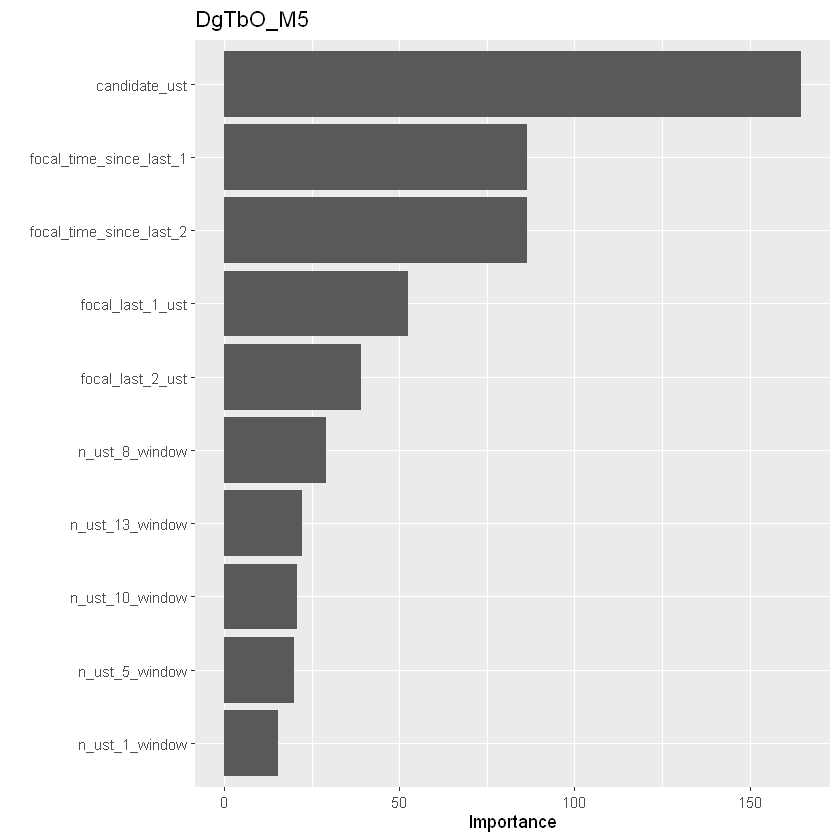

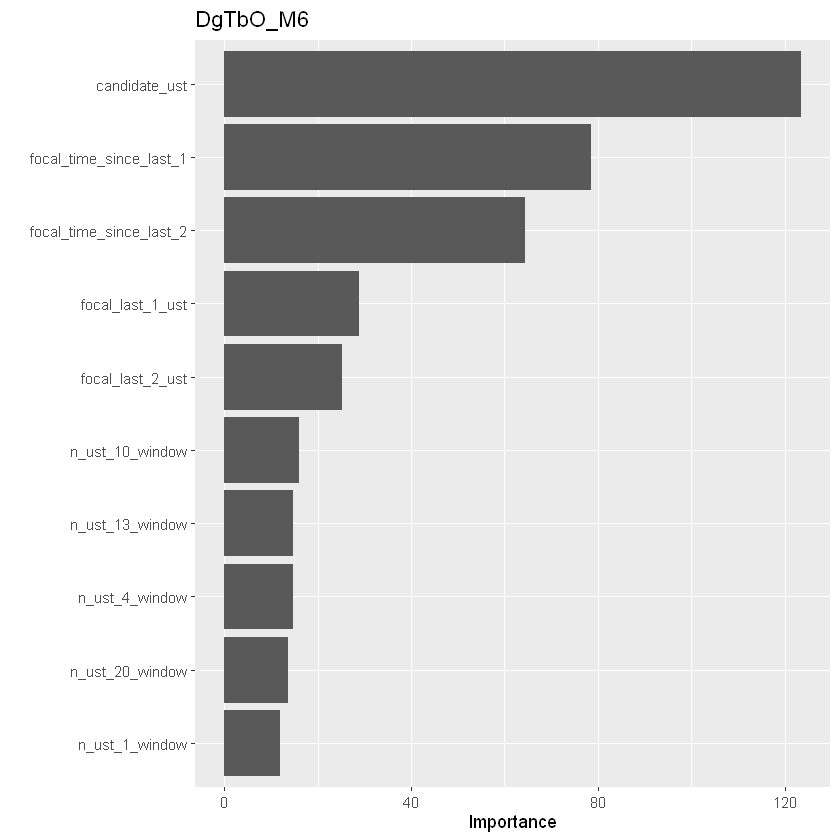

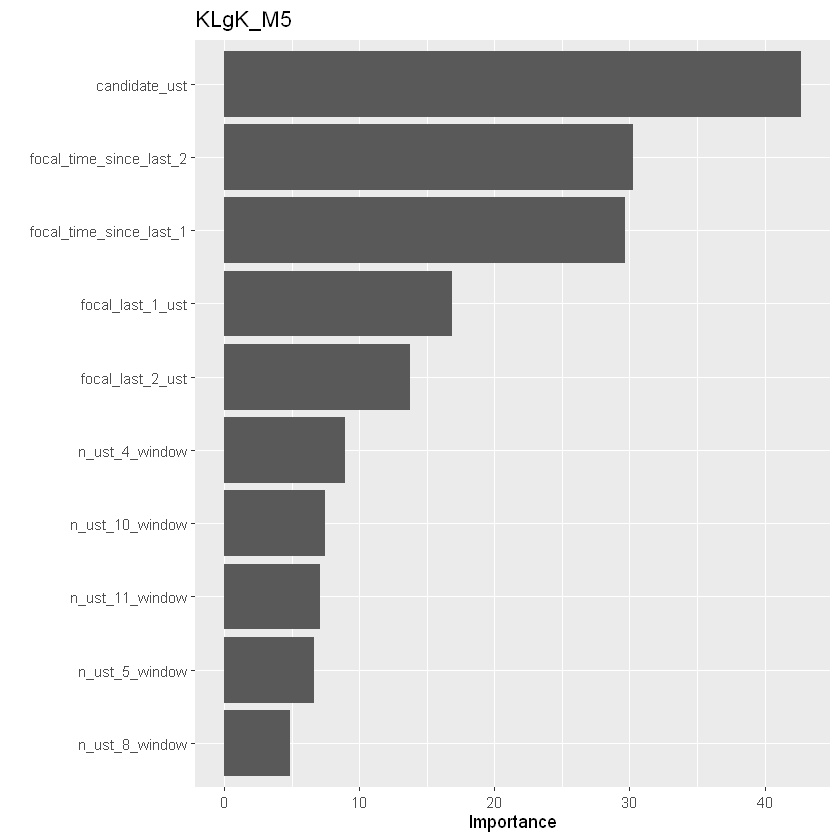

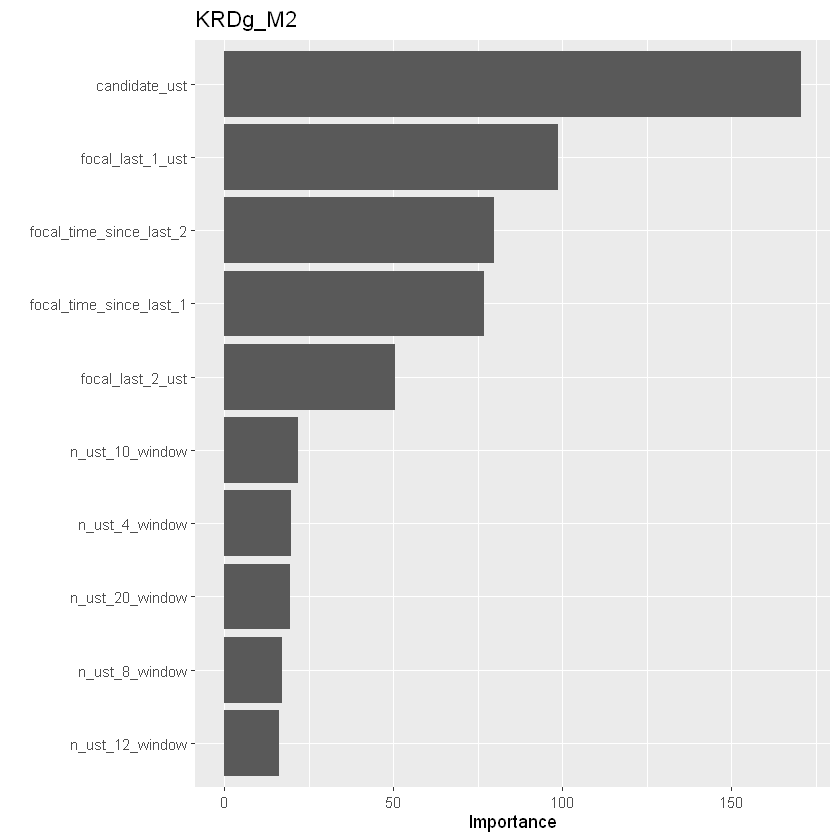

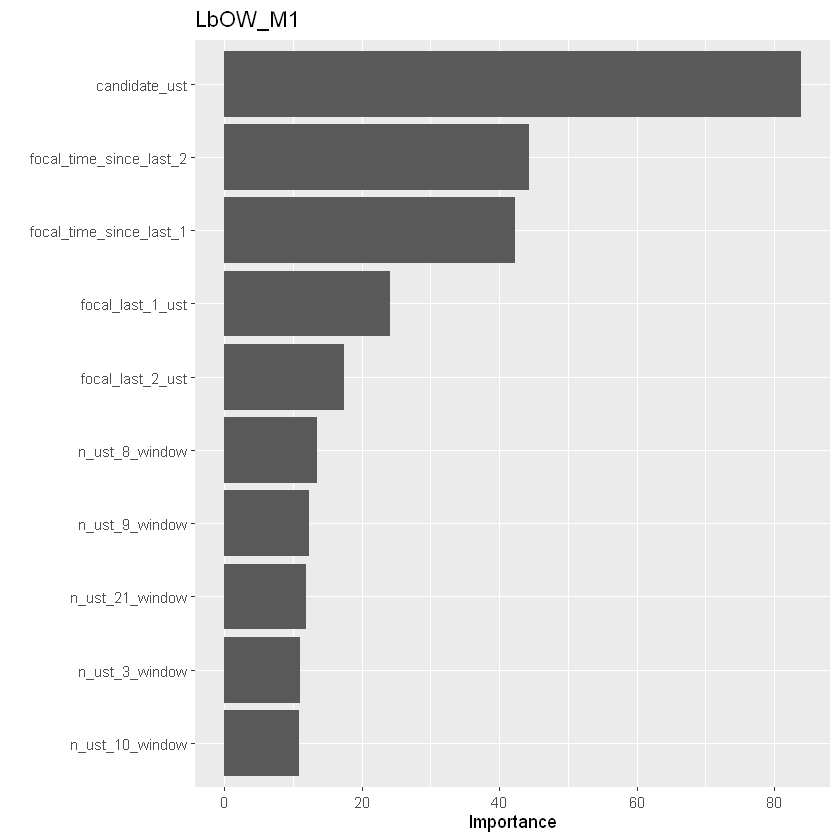

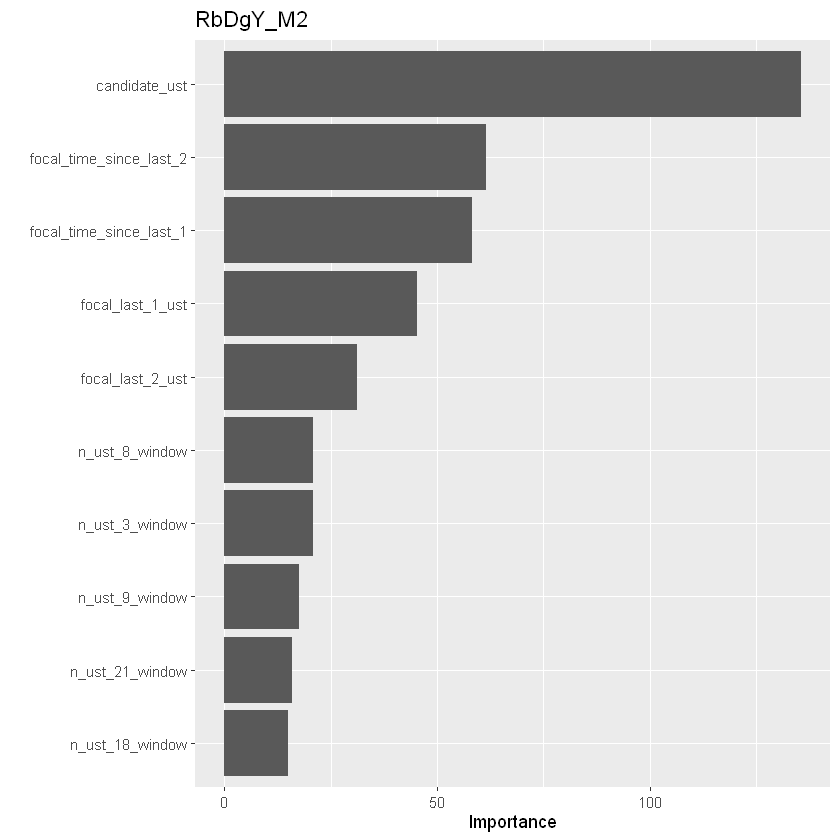

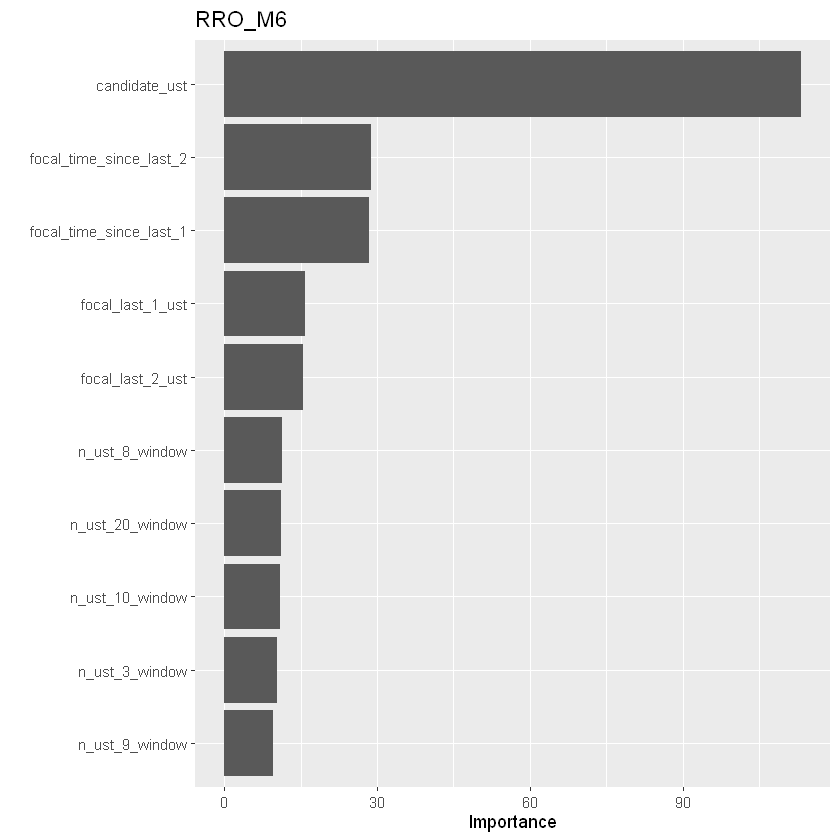

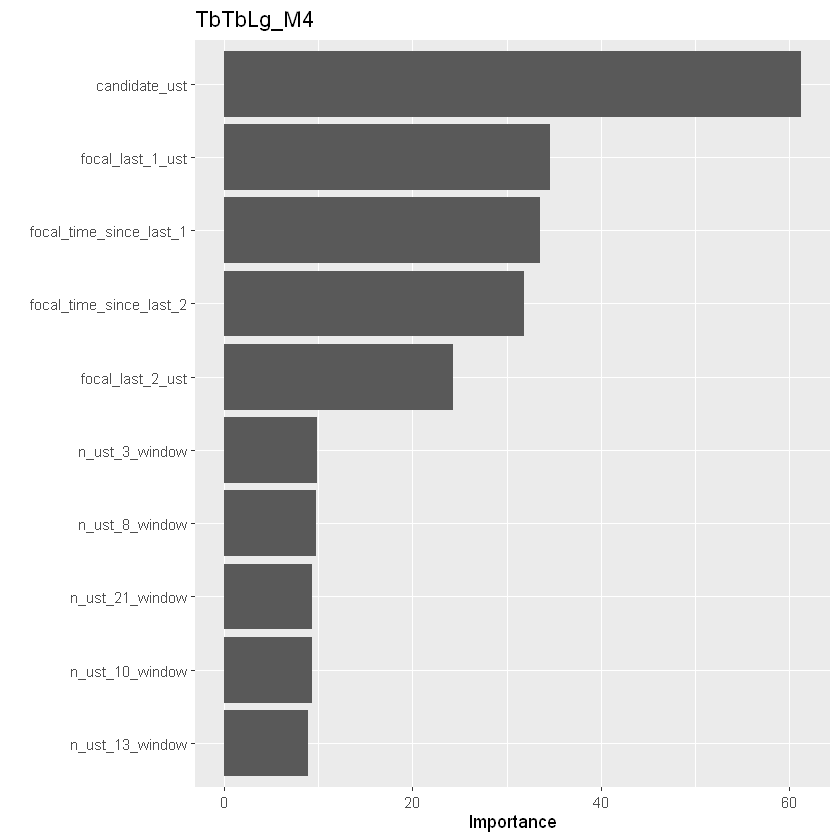

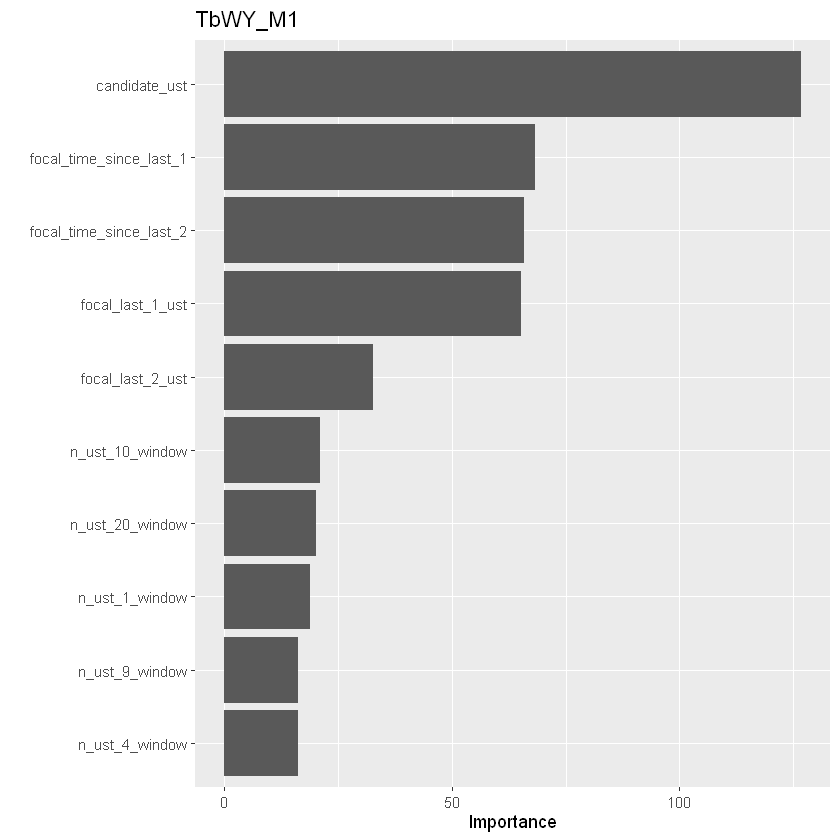

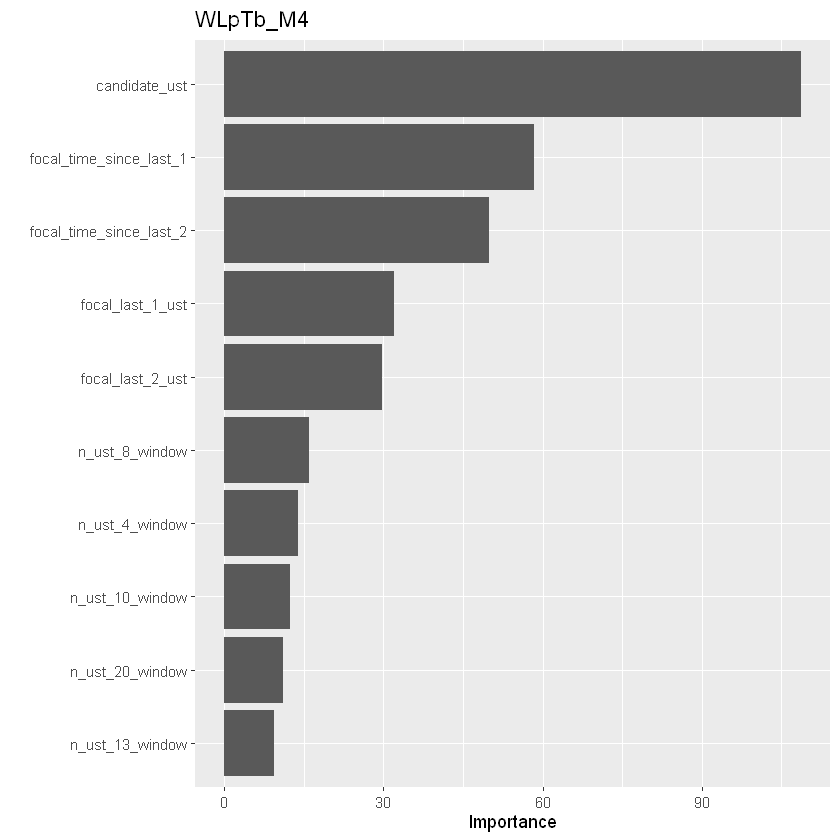

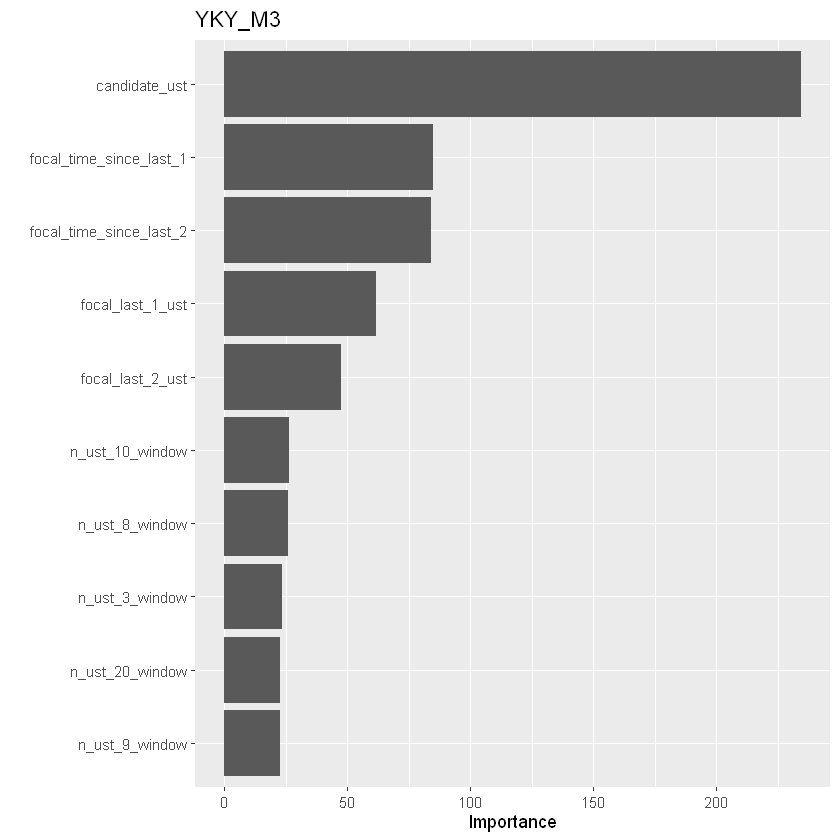

In [12]:
walk(male_results, ~ print(vip(.x$model %>% extract_fit_engine(), num_features = 10) + labs(title = .x$focal_male)))

Candidate-ranking metrics

In [13]:
per_male_metrics %>% summarise(
    macro_accuracy = mean(accuracy),
    macro_random_baseline = mean(random_baseline_accuracy),
    macro_top3_recall = mean(top3_recall),
    macro_mean_reciprocal_rank = mean(mean_reciprocal_rank),
    macro_mean_rank = mean(mean_rank)
)

macro_accuracy,macro_random_baseline,macro_top3_recall,macro_mean_reciprocal_rank,macro_mean_rank
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0.232453,0.04653498,0.4852892,0.4171783,5.090391


Comparison with notebook 03 (if its results were saved)

The comparison is indicative only: the two runs use different feature sets, and when `DROP_NA_EVENTS` is TRUE they also use different event sets and therefore different train/test splits.

In [14]:
baseline_path <- file.path(RESULTS_DIR, "candidate_match_test_metrics.csv")
if (file.exists(baseline_path)) {
    nb03 <- read_csv(baseline_path, show_col_types = FALSE) %>%
        select(focal_male, accuracy_nb03 = accuracy, top3_recall_nb03 = top3_recall, mrr_nb03 = mean_reciprocal_rank)
    per_male_metrics %>%
        select(focal_male, n_test_events, accuracy, random_baseline_accuracy, top3_recall, mean_reciprocal_rank) %>%
        left_join(nb03, by = "focal_male") %>%
        mutate(accuracy_change = accuracy - accuracy_nb03)
} else {
    message("No notebook 03 results found at ", baseline_path)
}

focal_male,n_test_events,accuracy,random_baseline_accuracy,top3_recall,mean_reciprocal_rank,accuracy_nb03,top3_recall_nb03,mrr_nb03,accuracy_change
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
DgTbO_M5,347,0.2420749,0.03571429,0.5129683,0.4370601,0.1514286,0.2742857,0.2702980,0.09064636
DgTbO_M6,297,0.1717172,0.03571429,0.4478114,0.3786191,0.1233333,0.2766667,0.2660056,0.04838384
KLgK_M5,152,0.1644737,0.05263158,0.3815789,0.3404448,0.1225806,0.3225806,0.2880223,0.04189304
KRDg_M2,303,0.3333333,0.03846154,0.5643564,0.4895879,0.1078431,0.2745098,0.2584806,0.22549020
LbOW_M1,207,0.1884058,0.05555556,0.4685990,0.4042360,0.1095238,0.3238095,0.2867574,0.07888199
RbDgY_M2,195,0.1897436,0.04761905,0.4615385,0.3881208,0.1522843,0.3756345,0.3312721,0.03745933
RRO_M6,158,0.2848101,0.05263158,0.5316456,0.4585313,0.1614907,0.3602484,0.3262272,0.12331944
TbTbLg_M4,217,0.1520737,0.05263158,0.4101382,0.3320373,0.1181818,0.2636364,0.2782545,0.03389191
TbWY_M1,178,0.4213483,0.05882353,0.6797753,0.5869408,0.2154696,0.4475138,0.3973848,0.20587870


Save results

In [15]:
# Save model results using the model name defined above.
dir.create(RESULTS_DIR, recursive = TRUE, showWarnings = FALSE)

per_male_metrics <- map_dfr(male_results, "metrics")
all_event_predictions <- map_dfr(male_results, ~ .x$event_predictions)
all_tuning_results <- map2_dfr(male_results, names(male_results), ~ .x$tuning_results %>% mutate(focal_male = .y))
all_features <- imap_dfr(model_data_by_male, ~ tibble(focal_male = .y, predictor = attr(.x, "predictor_cols")))

write_csv(per_male_metrics, file.path(RESULTS_DIR, paste0(MODEL_NAME, "_test_metrics.csv")))
write_csv(all_event_predictions, file.path(RESULTS_DIR, paste0(MODEL_NAME, "_event_predictions.csv")))
write_csv(all_tuning_results, file.path(RESULTS_DIR, paste0(MODEL_NAME, "_tuning_results.csv")))
write_csv(all_features, file.path(RESULTS_DIR, paste0(MODEL_NAME, "_features.csv")))
saveRDS(male_results, file.path(RESULTS_DIR, paste0(MODEL_NAME, "_models.rds")))

walk(male_results, function(result) {
    importance_chart <- result$model %>%
        extract_fit_engine() %>%
        vip(num_features = 10) +
        labs(title = paste(result$focal_male, MODEL_NAME)) +
        theme_bw()
    ggsave(
        file.path(RESULTS_DIR, paste0(MODEL_NAME, "_", result$focal_male, "_importance.png")),
        plot = importance_chart,
        width = 8,
        height = 6,
        units = "in"
    )
})

per_male_metrics

focal_male,n_test_events,accuracy,random_baseline_accuracy,macro_precision,macro_recall,top3_recall,mean_reciprocal_rank,mean_rank
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
DgTbO_M5,347,0.2420749,0.03571429,0.2357049,0.16234194,0.5129683,0.4370601,4.221902
DgTbO_M6,297,0.1717172,0.03571429,0.1625131,0.07561689,0.4478114,0.3786191,4.956229
KLgK_M5,152,0.1644737,0.05263158,0.1574402,0.12407244,0.3815789,0.3404448,6.072368
KRDg_M2,303,0.3333333,0.03846154,0.3124611,0.20842709,0.5643564,0.4895879,5.257426
LbOW_M1,207,0.1884058,0.05555556,0.1615193,0.11761243,0.4685990,0.4042360,4.328502
RbDgY_M2,195,0.1897436,0.04761905,0.1905369,0.10912490,0.4615385,0.3881208,5.312821
RRO_M6,158,0.2848101,0.05263158,0.2465823,0.15507937,0.5316456,0.4585313,4.544304
TbTbLg_M4,217,0.1520737,0.05263158,0.1946157,0.14168237,0.4101382,0.3320373,6.534562
TbWY_M1,178,0.4213483,0.05882353,0.3183958,0.24075238,0.6797753,0.5869408,3.230337
